# Olist E-commerce: Analysis and Dashboard Preparation

This analysis uses the SQLite star schema built from the public Olist Brazilian E-Commerce dataset. All notebook data is queried from `database/olist.sqlite3`; raw CSV files are not read here.

## 1. Project Overview and Data Model Summary

The goal is to identify revenue, product, delivery, customer, review, and payment patterns for dashboard use. The star schema contains `dim_customers`, `dim_products`, `dim_sellers`, `dim_date`, `dim_geolocation`, `fact_sales`, `fact_payments`, and `fact_reviews`. `fact_sales` is one row per order item; `fact_payments` is one row per payment; `fact_reviews` is one row per review.

Revenue is `SUM(price)` from `fact_sales`, excluding `canceled` and `unavailable` orders. Trend analysis excludes all of 2016 and the latest purchase month because it is incomplete. Rates and averages used for rankings require at least 100 delivered items per seller state or 50 reviews per category. The thresholds are named constants below.

### Table Row Counts and Analysis Setup

The next code cell defines shared thresholds and helpers, then queries every dimension and fact table for its loaded row count. The trend filter excludes 2016 and the latest incomplete month; on this database, that is September 2018, leaving January 2017 through August 2018.

## 2. Define Constants and Helper Functions

`MIN_ITEMS_PER_STATE` is 100 delivered items and `MIN_REVIEWS_PER_CATEGORY` is 50 reviews. The notebook imports both thresholds, the SQLite database path, and the figure directory from `src.config`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sqlalchemy import create_engine, text

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src import config

MIN_ITEMS_PER_STATE = config.MIN_DELIVERED_ITEMS_PER_STATE
MIN_REVIEWS_PER_CATEGORY = config.MIN_REVIEWS_PER_CATEGORY
DATABASE_PATH = config.DATABASE_PATH
FIGURES_DIR = config.NOTEBOOK_FIGURES_DIR
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="muted")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titleweight": "bold"})
engine = create_engine(f"sqlite:///{DATABASE_PATH.as_posix()}")


def query_df(sql: str, params: dict[str, int | str] | None = None) -> pd.DataFrame:
    """Run a SQL query against the project SQLite database and return a DataFrame."""
    with engine.connect() as connection:
        return pd.read_sql_query(text(sql), connection, params=params or {})


def save_chart(figure: plt.Figure, filename: str) -> Path:
    """Save a chart as a PNG in the configured notebook figures directory."""
    output_path = FIGURES_DIR / filename
    figure.tight_layout()
    figure.savefig(output_path, dpi=160, bbox_inches="tight")
    return output_path

table_counts = query_df("""
SELECT 'dim_customers' AS table_name, COUNT(*) AS row_count FROM dim_customers
UNION ALL SELECT 'dim_products', COUNT(*) FROM dim_products
UNION ALL SELECT 'dim_sellers', COUNT(*) FROM dim_sellers
UNION ALL SELECT 'dim_date', COUNT(*) FROM dim_date
UNION ALL SELECT 'dim_geolocation', COUNT(*) FROM dim_geolocation
UNION ALL SELECT 'fact_sales', COUNT(*) FROM fact_sales
UNION ALL SELECT 'fact_payments', COUNT(*) FROM fact_payments
UNION ALL SELECT 'fact_reviews', COUNT(*) FROM fact_reviews
""")
table_counts

,table_name,row_count
0,dim_customers,99441
1,dim_products,32951
2,dim_sellers,3095
3,dim_date,774
4,dim_geolocation,19015
5,fact_sales,112650
6,fact_payments,103886
7,fact_reviews,98410


## 3. Revenue Trends

The trend series excludes all of 2016 and the latest month in the database. The latest stored purchase timestamp is in September 2018, so September is treated as incomplete; displayed trends cover January 2017 through August 2018. Revenue excludes canceled and unavailable orders.

In [2]:
monthly = query_df("""
WITH latest AS (
    SELECT date(MAX(purchase_timestamp), 'start of month') AS latest_month
    FROM fact_sales
), totals AS (
    SELECT d.year, d.month, d.month_name,
           strftime('%Y-%m', d.full_date) AS year_month,
           SUM(f.price) AS revenue,
           COUNT(DISTINCT f.order_id) AS orders
    FROM fact_sales AS f
    JOIN dim_date AS d ON d.date_key = f.purchase_date_key
    CROSS JOIN latest AS l
    WHERE f.order_status NOT IN ('canceled', 'unavailable')
      AND d.year > 2016
      AND date(d.full_date, 'start of month') < l.latest_month
    GROUP BY d.year, d.month, d.month_name, year_month
)
SELECT year, month, month_name, year_month, revenue, orders,
       revenue * 1.0 / NULLIF(orders, 0) AS average_order_value,
       100.0 * (revenue - LAG(revenue) OVER (ORDER BY year, month))
         / NULLIF(LAG(revenue) OVER (ORDER BY year, month), 0) AS mom_growth_pct
FROM totals
ORDER BY year, month
""")
monthly.head()

,year,month,month_name,year_month,revenue,orders,average_order_value,mom_growth_pct
0,2017,1,January,2017-01,120098.27,787,152.602630,NaN
1,2017,2,February,2017-02,244959.35,1718,142.584022,103.965761
2,2017,3,March,2017-03,368341.32,2617,140.749454,50.368345
3,2017,4,April,2017-04,353842.98,2377,148.861161,-3.936116
4,2017,5,May,2017-05,503159.19,3640,138.230547,42.198438


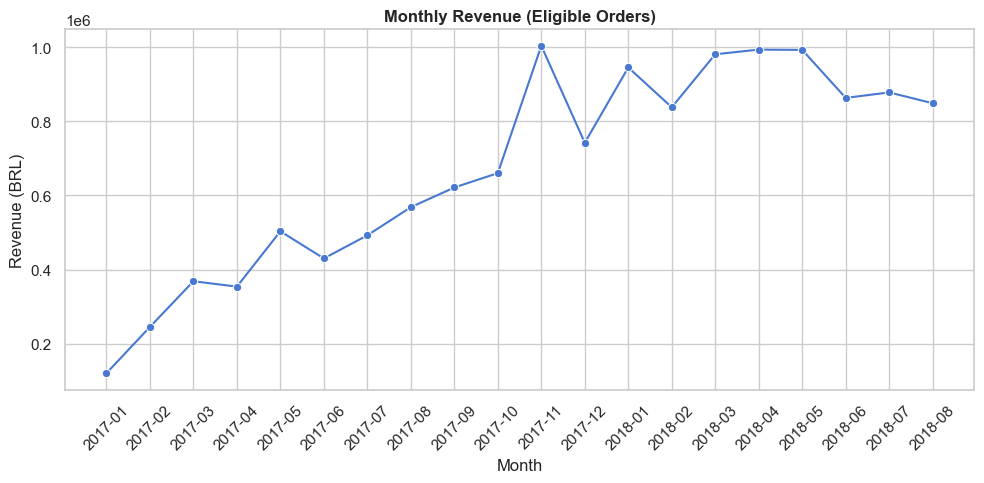

In [3]:
fig, ax = plt.subplots()
sns.lineplot(data=monthly, x="year_month", y="revenue", marker="o", ax=ax)
ax.set(title="Monthly Revenue (Eligible Orders)", xlabel="Month", ylabel="Revenue (BRL)")
ax.tick_params(axis="x", rotation=45)
save_chart(fig, "monthly_revenue.png")
plt.show()
plt.close(fig)

**Insight:** Monthly eligible-order revenue varies over the complete-month trend window; the series excludes canceled/unavailable orders, 2016, and the final partial month.

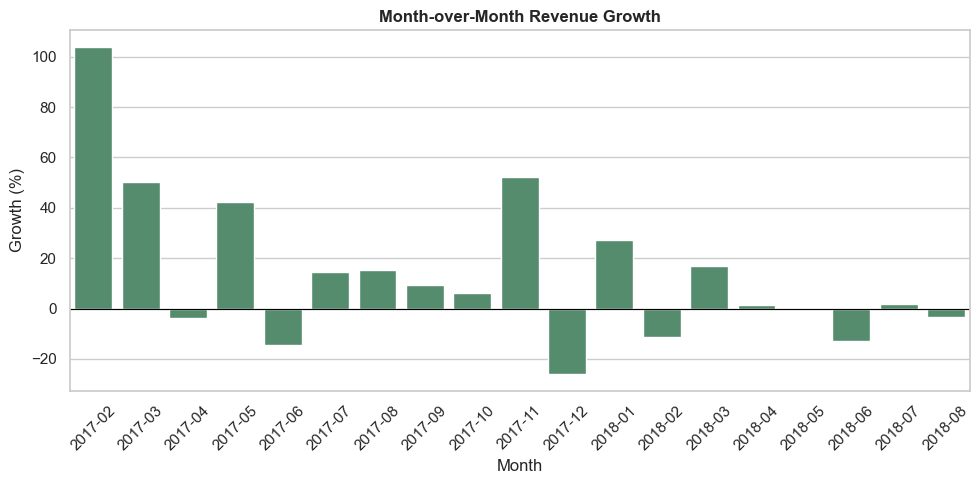

In [4]:
fig, ax = plt.subplots()
sns.barplot(data=monthly.dropna(subset=["mom_growth_pct"]), x="year_month", y="mom_growth_pct", color="#4c956c", ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Month-over-Month Revenue Growth", xlabel="Month", ylabel="Growth (%)")
ax.tick_params(axis="x", rotation=45)
save_chart(fig, "monthly_revenue_growth.png")
plt.show()
plt.close(fig)

**Insight:** The growth series compares each complete month with the immediately preceding complete month; positive and negative bars show the timing of expansion and contraction.

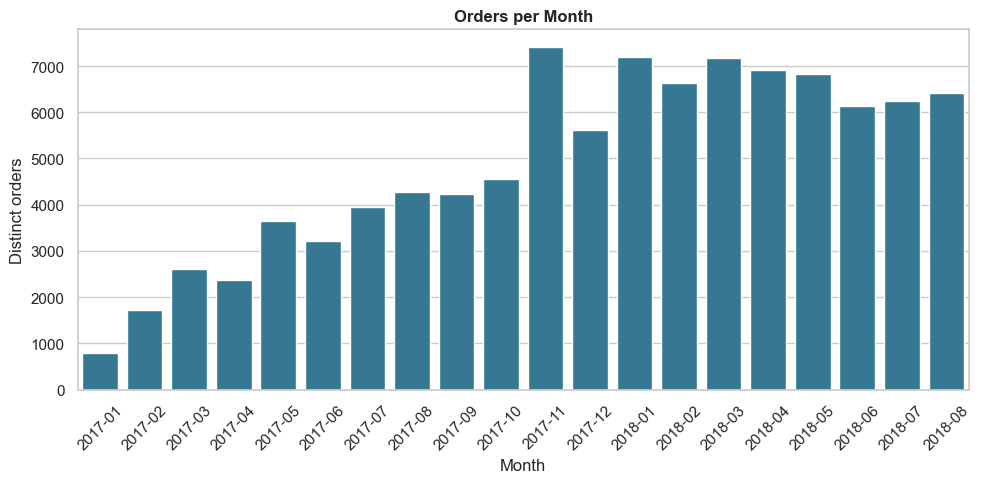

In [5]:
fig, ax = plt.subplots()
sns.barplot(data=monthly, x="year_month", y="orders", color="#277da1", ax=ax)
ax.set(title="Orders per Month", xlabel="Month", ylabel="Distinct orders")
ax.tick_params(axis="x", rotation=45)
save_chart(fig, "orders_per_month.png")
plt.show()
plt.close(fig)

**Insight:** Monthly order volume tracks order activity independently of item counts, since each order is counted once even when it contains multiple items.

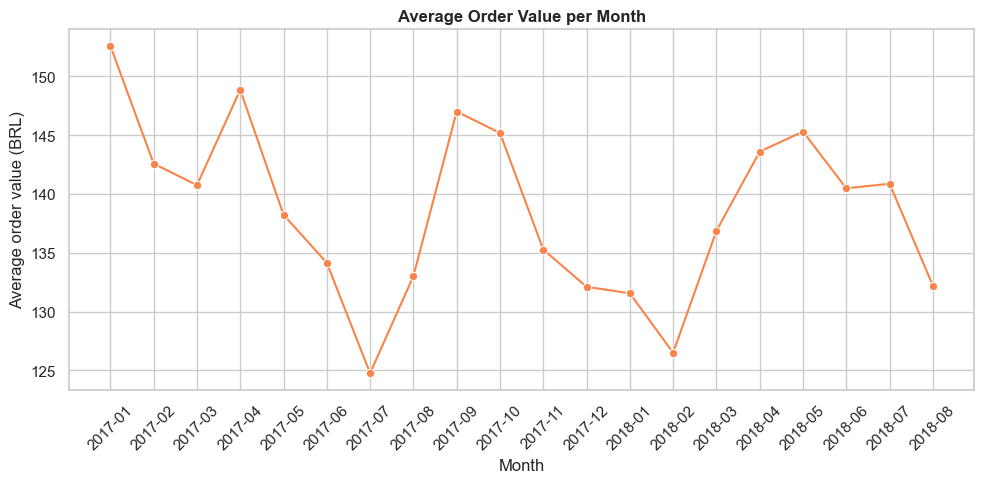

In [6]:
fig, ax = plt.subplots()
sns.lineplot(data=monthly, x="year_month", y="average_order_value", marker="o", color="#f9844a", ax=ax)
ax.set(title="Average Order Value per Month", xlabel="Month", ylabel="Average order value (BRL)")
ax.tick_params(axis="x", rotation=45)
save_chart(fig, "average_order_value.png")
plt.show()
plt.close(fig)

**Insight:** Average order value is monthly eligible revenue divided by distinct eligible orders, so the measure is not inflated by orders with multiple items.

## 4. Product Analysis

Category revenue uses eligible order-item `price` across the full dataset period; canceled and unavailable orders are excluded.

In [7]:
category_revenue = query_df("""
SELECT p.product_category_name_english AS category,
       SUM(f.price) AS revenue,
       COUNT(*) AS items
FROM fact_sales AS f
JOIN dim_products AS p ON p.product_id = f.product_id
WHERE f.order_status NOT IN ('canceled', 'unavailable')
GROUP BY p.product_category_name_english
ORDER BY revenue DESC
""")
top_categories = category_revenue.head(10).copy()
top10_share_pct = 100 * top_categories["revenue"].sum() / category_revenue["revenue"].sum()
top_categories

,category,revenue,items
0,health_beauty,1255695.13,9634
1,watches_gifts,1198185.21,5970
2,bed_bath_table,1035964.06,11097
3,sports_leisure,979740.92,8590
4,computers_accessories,904322.02,7781
5,furniture_decor,727465.05,8298
6,housewares,626825.80,6915
7,cool_stuff,620770.49,3779
8,auto,586585.73,4204
9,garden_tools,481009.94,4328


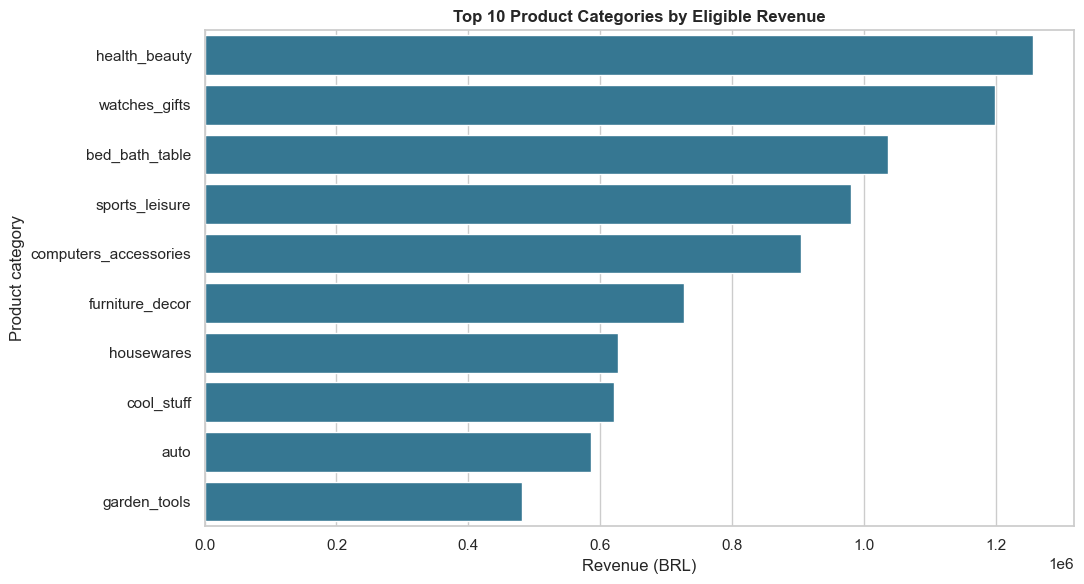

In [8]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=top_categories, x="revenue", y="category", color="#277da1", ax=ax)
ax.set(title="Top 10 Product Categories by Eligible Revenue", xlabel="Revenue (BRL)", ylabel="Product category")
save_chart(fig, "top_categories_revenue.png")
plt.show()
plt.close(fig)

**Insight:** The leading categories concentrate a meaningful share of eligible sales; the plotted ranking makes the largest category and the steepness of the top-10 distribution easy to compare.

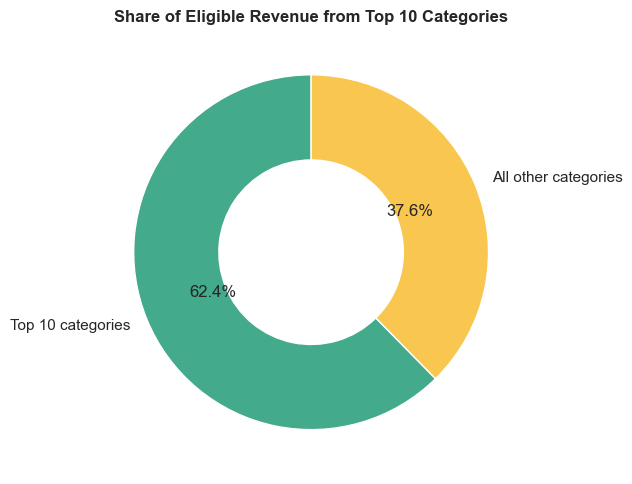

In [9]:
fig, ax = plt.subplots()
ax.pie(
    [top10_share_pct, 100 - top10_share_pct],
    labels=["Top 10 categories", "All other categories"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#43aa8b", "#f9c74f"],
    wedgeprops={"width": 0.48},
)
ax.set(title="Share of Eligible Revenue from Top 10 Categories")
save_chart(fig, "top10_category_revenue_share.png")
plt.show()
plt.close(fig)

**Insight:** The top 10 categories account for `top10_share_pct` percent of eligible revenue, leaving the remainder spread across the long tail. The exact percentage is calculated above.

## 5. Delivery Performance

Seller-state late rates include only orders with a delivery result and states with at least `MIN_ITEMS_PER_STATE` delivered items. Delivery duration is summarized at one row per order. Review comparisons first aggregate item delivery outcomes to the order level, then join reviews, so an order with multiple items does not multiply review rows.

In [10]:
delivery_state = query_df("""
SELECT s.seller_state,
       COUNT(*) AS delivered_items,
       SUM(CASE WHEN f.is_late = 1 THEN 1 ELSE 0 END) AS late_items,
       100.0 * SUM(CASE WHEN f.is_late = 1 THEN 1 ELSE 0 END) / COUNT(*) AS late_rate_pct
FROM fact_sales AS f
JOIN dim_sellers AS s ON s.seller_id = f.seller_id
WHERE f.is_late IS NOT NULL
GROUP BY s.seller_state
HAVING COUNT(*) >= :minimum_items
ORDER BY late_rate_pct DESC
""", {"minimum_items": MIN_ITEMS_PER_STATE})
delivery_state

,seller_state,delivered_items,late_items,late_rate_pct
0,MA,402,95,23.631841
1,SP,78600,6698,8.521628
2,RJ,4689,380,8.104073
3,DF,883,59,6.681767
4,ES,364,24,6.593407
5,PR,8487,548,6.456934
6,SC,4000,235,5.875000
7,MG,8602,477,5.545222
8,BA,624,34,5.448718
9,MT,144,7,4.861111


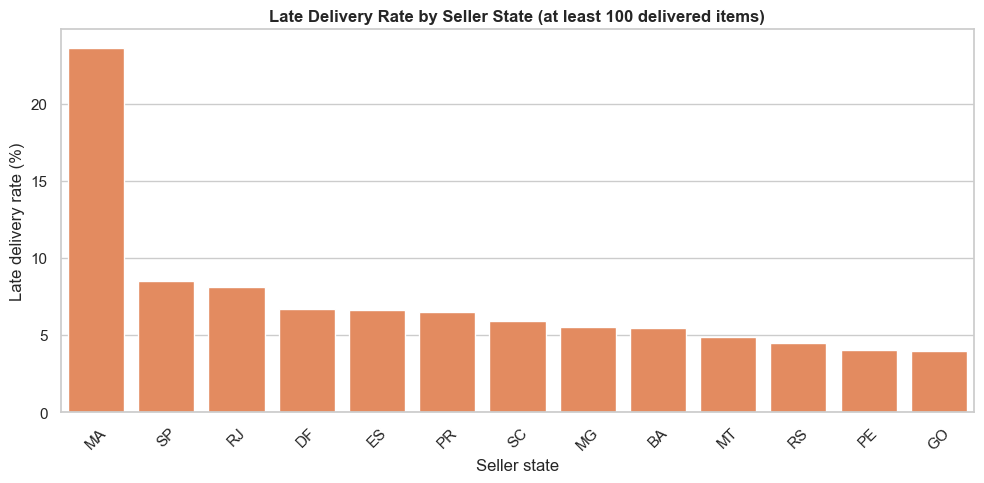

In [11]:
fig, ax = plt.subplots()
sns.barplot(data=delivery_state, x="seller_state", y="late_rate_pct", color="#f9844a", ax=ax)
ax.set(title=f"Late Delivery Rate by Seller State (at least {MIN_ITEMS_PER_STATE} delivered items)", xlabel="Seller state", ylabel="Late delivery rate (%)")
ax.tick_params(axis="x", rotation=45)
save_chart(fig, "late_delivery_rate_by_seller_state.png")
plt.show()
plt.close(fig)

**Insight:** Only seller states meeting the 100-item minimum are ranked; this volume floor reduces the influence of small, volatile samples.

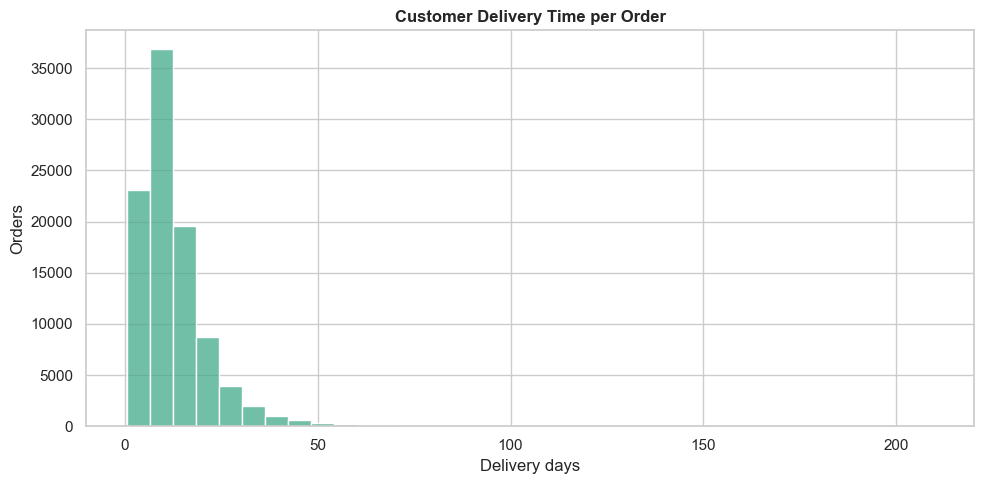

In [12]:
delivery_days = query_df("""
SELECT order_id, MAX(delivery_days) AS delivery_days
FROM fact_sales
WHERE delivery_days IS NOT NULL
GROUP BY order_id
ORDER BY order_id
""")
fig, ax = plt.subplots()
sns.histplot(data=delivery_days, x="delivery_days", bins=35, color="#43aa8b", ax=ax)
ax.set(title="Customer Delivery Time per Order", xlabel="Delivery days", ylabel="Orders")
save_chart(fig, "delivery_days_distribution.png")
plt.show()
plt.close(fig)

**Insight:** The histogram uses one observation per delivered order rather than one per item, showing the distribution without overweighting large baskets.

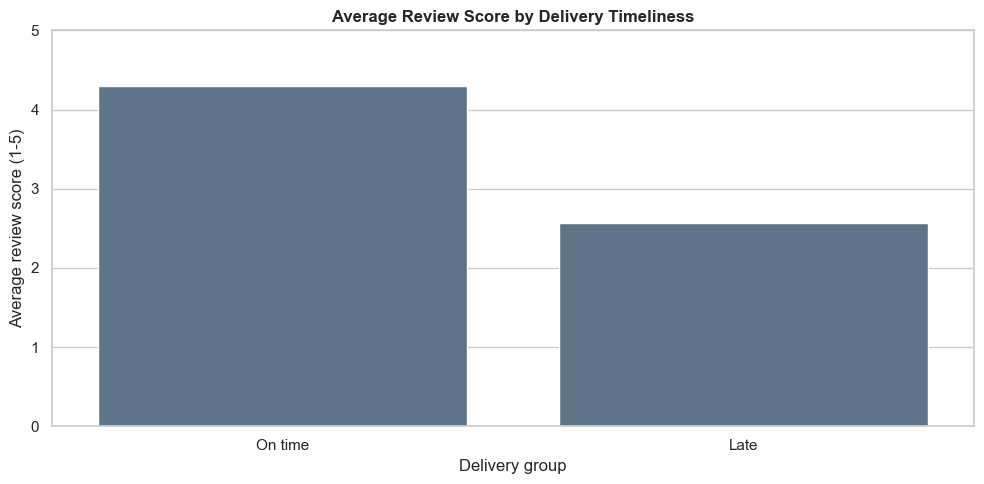

In [13]:
delivery_review = query_df("""
WITH order_delivery AS (
    SELECT order_id, MAX(is_late) AS is_late
    FROM fact_sales
    WHERE is_late IS NOT NULL
    GROUP BY order_id
), order_reviews AS (
    SELECT order_id, AVG(review_score) AS order_average_review_score
    FROM fact_reviews
    WHERE review_score IS NOT NULL
    GROUP BY order_id
)
SELECT CASE WHEN d.is_late = 1 THEN 'Late' ELSE 'On time' END AS delivery_group,
       COUNT(*) AS orders,
       AVG(r.order_average_review_score) AS average_review_score
FROM order_delivery AS d
JOIN order_reviews AS r ON r.order_id = d.order_id
GROUP BY d.is_late
ORDER BY d.is_late
""")
fig, ax = plt.subplots()
sns.barplot(data=delivery_review, x="delivery_group", y="average_review_score", color="#577590", ax=ax)
ax.set(title="Average Review Score by Delivery Timeliness", xlabel="Delivery group", ylabel="Average review score (1-5)", ylim=(0, 5))
save_chart(fig, "review_score_by_delivery.png")
plt.show()
plt.close(fig)

**Insight:** Review scores are averaged within each order before comparing delivery groups, ensuring each review-bearing order contributes once to the group average regardless of its item count.

## 6. Customer Analysis

Repeat behavior is defined by the number of distinct orders per `customer_unique_id`. State revenue uses eligible order-item prices and excludes canceled/unavailable orders.

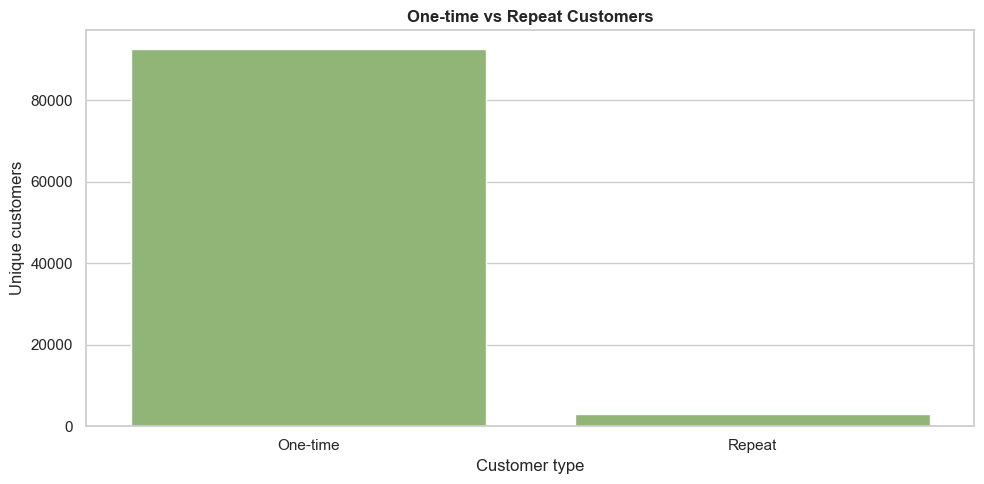

In [14]:
customer_frequency = query_df("""
WITH customer_orders AS (
    SELECT DISTINCT c.customer_unique_id, f.order_id
    FROM fact_sales AS f
    JOIN dim_customers AS c ON c.customer_id = f.customer_id
), customer_counts AS (
    SELECT customer_unique_id, COUNT(*) AS order_count
    FROM customer_orders
    GROUP BY customer_unique_id
)
SELECT CASE WHEN order_count > 1 THEN 'Repeat' ELSE 'One-time' END AS customer_type,
       COUNT(*) AS customers
FROM customer_counts
GROUP BY customer_type
ORDER BY customer_type
""")
fig, ax = plt.subplots()
sns.barplot(data=customer_frequency, x="customer_type", y="customers", color="#90be6d", ax=ax)
ax.set(title="One-time vs Repeat Customers", xlabel="Customer type", ylabel="Unique customers")
save_chart(fig, "repeat_vs_one_time_customers.png")
plt.show()
plt.close(fig)

**Insight:** The comparison counts customer identities rather than customer records, so multiple Olist customer IDs for the same person are not treated as separate people.

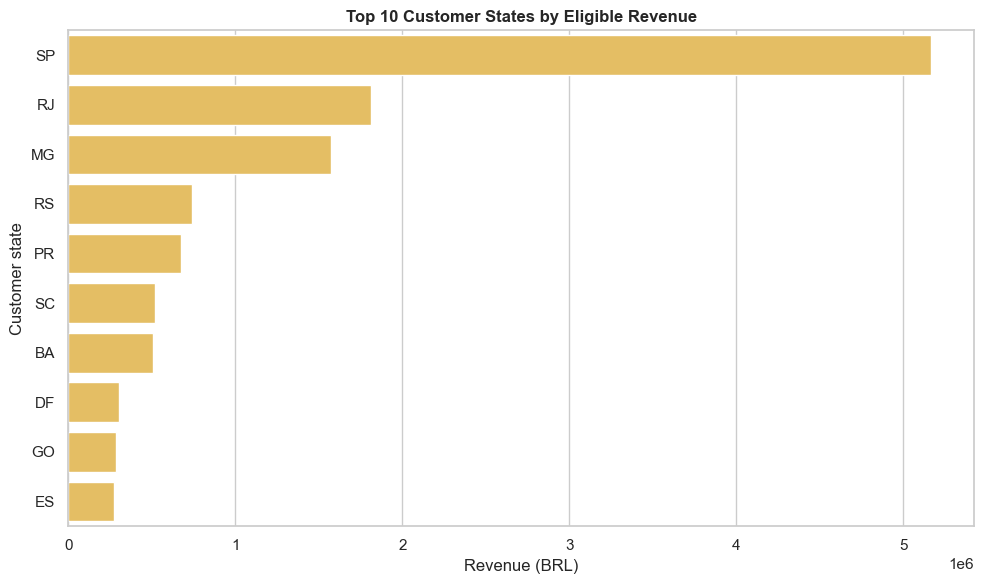

In [15]:
customer_state_revenue = query_df("""
SELECT c.customer_state,
       SUM(f.price) AS revenue,
       COUNT(DISTINCT f.order_id) AS orders
FROM fact_sales AS f
JOIN dim_customers AS c ON c.customer_id = f.customer_id
WHERE f.order_status NOT IN ('canceled', 'unavailable')
GROUP BY c.customer_state
ORDER BY revenue DESC
LIMIT 10
""")
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=customer_state_revenue, x="revenue", y="customer_state", color="#f9c74f", ax=ax)
ax.set(title="Top 10 Customer States by Eligible Revenue", xlabel="Revenue (BRL)", ylabel="Customer state")
save_chart(fig, "top_customer_states_revenue.png")
plt.show()
plt.close(fig)

**Insight:** The state ranking reflects eligible merchandise price across all available years, not the shorter trend window.

## 7. Review Analysis

Review-score distribution uses all non-null review scores. Category averages include eligible orders only and are shown only for categories with at least `MIN_REVIEWS_PER_CATEGORY` distinct reviews.

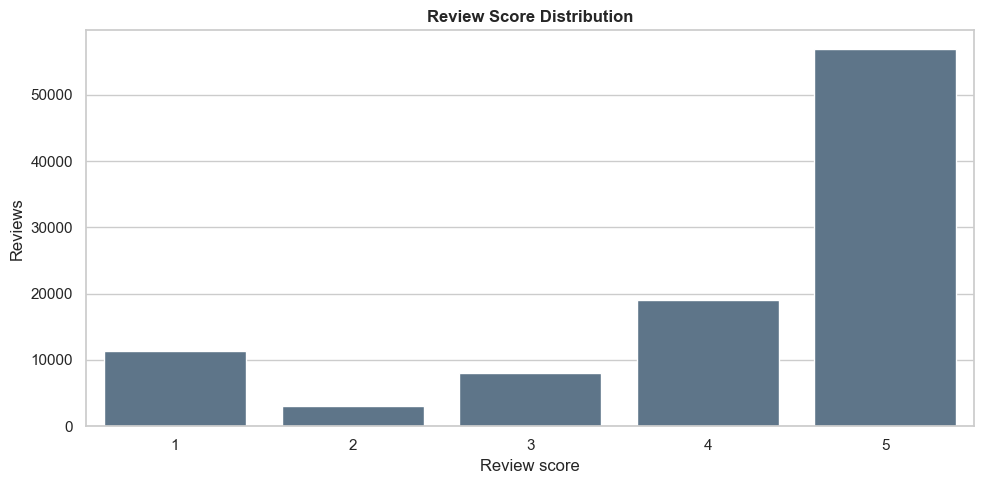

In [16]:
review_scores = query_df("""
SELECT review_score, COUNT(*) AS reviews
FROM fact_reviews
WHERE review_score IS NOT NULL
GROUP BY review_score
ORDER BY review_score
""")
fig, ax = plt.subplots()
sns.barplot(data=review_scores, x="review_score", y="reviews", color="#577590", ax=ax)
ax.set(title="Review Score Distribution", xlabel="Review score", ylabel="Reviews")
save_chart(fig, "review_score_distribution.png")
plt.show()
plt.close(fig)

**Insight:** The score distribution shows whether customer feedback is concentrated at the low, middle, or high end of the five-point scale.

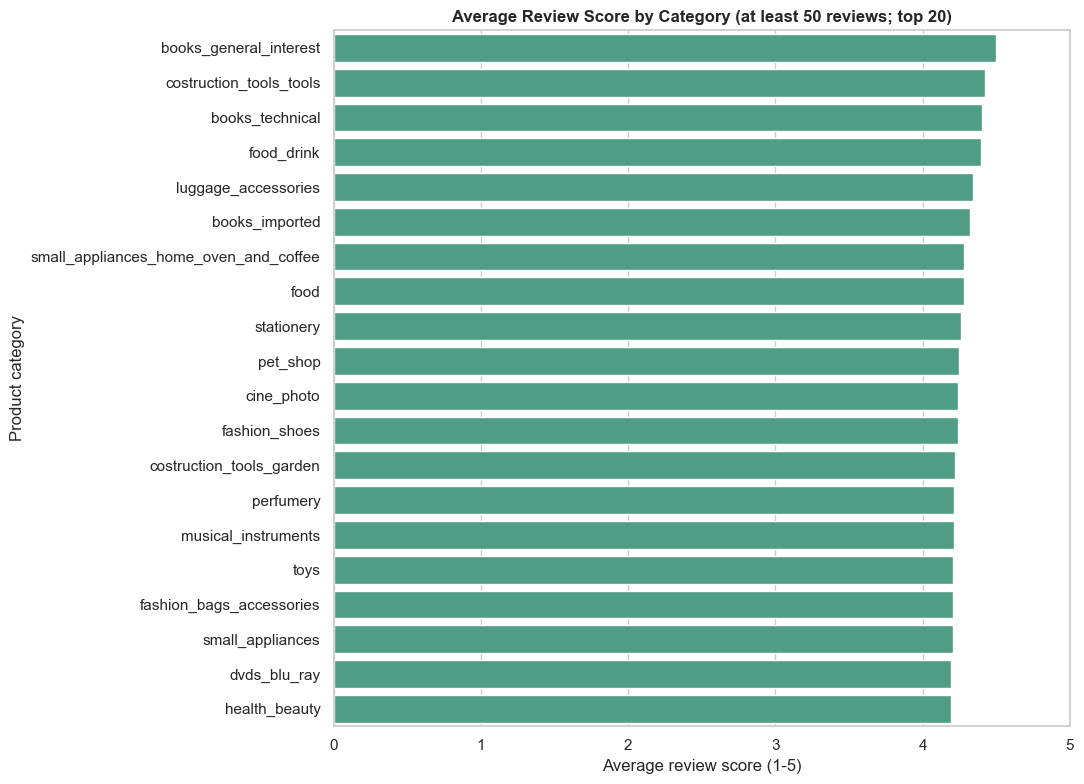

In [17]:
category_reviews = query_df("""
WITH order_categories AS (
    SELECT DISTINCT f.order_id, p.product_category_name_english AS category
    FROM fact_sales AS f
    JOIN dim_products AS p ON p.product_id = f.product_id
    WHERE f.order_status NOT IN ('canceled', 'unavailable')
)
SELECT oc.category,
       COUNT(DISTINCT r.review_id) AS review_count,
       AVG(r.review_score) AS average_review_score
FROM order_categories AS oc
JOIN fact_reviews AS r ON r.order_id = oc.order_id
WHERE r.review_score IS NOT NULL
GROUP BY oc.category
HAVING COUNT(DISTINCT r.review_id) >= :minimum_reviews
ORDER BY average_review_score DESC, review_count DESC
""", {"minimum_reviews": MIN_REVIEWS_PER_CATEGORY})
fig, ax = plt.subplots(figsize=(11, 8))
sns.barplot(data=category_reviews.head(20), x="average_review_score", y="category", color="#43aa8b", ax=ax)
ax.set(title=f"Average Review Score by Category (at least {MIN_REVIEWS_PER_CATEGORY} reviews; top 20)", xlabel="Average review score (1-5)", ylabel="Product category", xlim=(0, 5))
save_chart(fig, "average_review_score_by_category.png")
plt.show()
plt.close(fig)

**Insight:** Only categories meeting the 50-review floor are ranked, making comparisons less sensitive to a handful of unusually high or low ratings.

## 8. Payment Analysis

Payment analysis is kept at payment grain. Payment-type amounts are restricted to orders that have at least one sales item outside the canceled/unavailable statuses; payments are not joined to item rows.

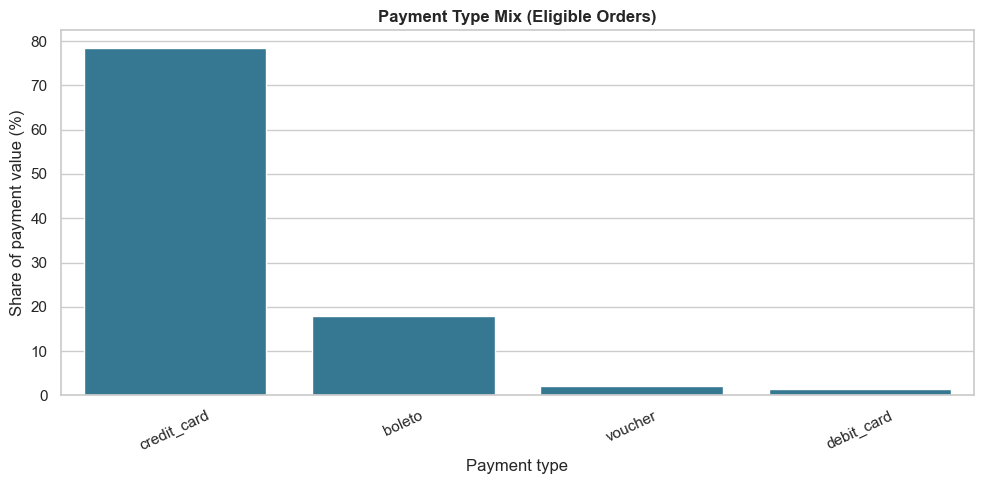

In [18]:
payment_mix = query_df("""
WITH eligible_orders AS (
    SELECT DISTINCT order_id
    FROM fact_sales
    WHERE order_status NOT IN ('canceled', 'unavailable')
)
SELECT p.payment_type, SUM(p.payment_value) AS payment_value
FROM fact_payments AS p
JOIN eligible_orders AS e ON e.order_id = p.order_id
GROUP BY p.payment_type
ORDER BY payment_value DESC
""")
payment_mix["share_pct"] = 100 * payment_mix["payment_value"] / payment_mix["payment_value"].sum()
fig, ax = plt.subplots()
sns.barplot(data=payment_mix, x="payment_type", y="share_pct", color="#277da1", ax=ax)
ax.set(title="Payment Type Mix (Eligible Orders)", xlabel="Payment type", ylabel="Share of payment value (%)")
ax.tick_params(axis="x", rotation=25)
save_chart(fig, "payment_type_mix.png")
plt.show()
plt.close(fig)

**Insight:** Payment mix is calculated from payment records for eligible orders, avoiding the item-level join that would multiply payment value.

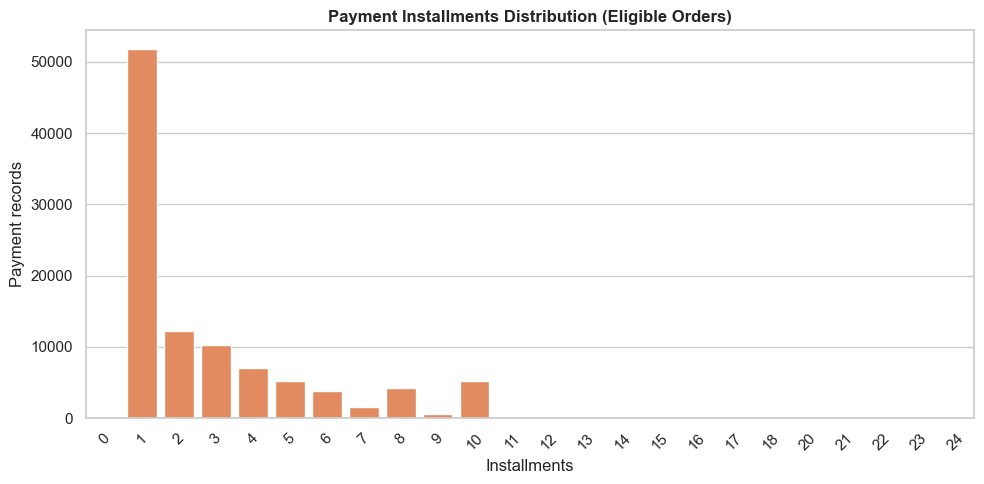

In [19]:
installments = query_df("""
WITH eligible_orders AS (
    SELECT DISTINCT order_id
    FROM fact_sales
    WHERE order_status NOT IN ('canceled', 'unavailable')
)
SELECT p.payment_installments, COUNT(*) AS payment_records
FROM fact_payments AS p
JOIN eligible_orders AS e ON e.order_id = p.order_id
GROUP BY p.payment_installments
ORDER BY p.payment_installments
""")
fig, ax = plt.subplots()
sns.barplot(data=installments, x="payment_installments", y="payment_records", color="#f9844a", ax=ax)
ax.set(title="Payment Installments Distribution (Eligible Orders)", xlabel="Installments", ylabel="Payment records")
ax.tick_params(axis="x", rotation=45)
save_chart(fig, "payment_installments_distribution.png")
plt.show()
plt.close(fig)

**Insight:** The installment distribution describes payment records rather than orders; orders paid in multiple installments or with split payment methods can contribute multiple records.

## 9. Key Insights and Business Recommendations

The findings below are calculated from the displayed aggregates. They use eligible merchandise revenue for financial rankings, complete months for trend conclusions, and the volume thresholds defined at the top of the notebook.

In [ ]:
from IPython.display import Markdown, display

peak_month = monthly.loc[monthly["revenue"].idxmax()]
bottom_month = monthly.loc[monthly["revenue"].idxmin()]
top_category = top_categories.iloc[0]
highest_late_state = delivery_state.iloc[0]
review_by_delivery = delivery_review.set_index("delivery_group")
repeat_count = int(customer_frequency.loc[customer_frequency["customer_type"] == "Repeat", "customers"].iloc[0])
customer_total = int(customer_frequency["customers"].sum())
top_customer_state = customer_state_revenue.iloc[0]
top_payment = payment_mix.iloc[0]

insights = [
    f"**Revenue peak:** {peak_month['month_name']} {int(peak_month['year'])} generated BRL {peak_month['revenue']:,.0f}, compared with BRL {bottom_month['revenue']:,.0f} in the lowest complete trend month.",
    f"**Category concentration:** the top 10 product categories represented {top10_share_pct:.1f}% of eligible revenue; {top_category['category']} led at BRL {top_category['revenue']:,.0f}.",
    f"**Delivery risk:** {highest_late_state['seller_state']} had the highest late rate ({highest_late_state['late_rate_pct']:.1f}%) among states with at least {MIN_ITEMS_PER_STATE} delivered items.",
    f"**Delivery and experience:** average review scores were {review_by_delivery.loc['On time', 'average_review_score']:.2f} on time versus {review_by_delivery.loc['Late', 'average_review_score']:.2f} for late orders.",
    f"**Customer retention:** {repeat_count / customer_total:.1%} of purchasing customer identities placed more than one order; prioritize retention campaigns to expand this cohort.",
    f"**Geographic demand:** {top_customer_state['customer_state']} was the largest customer-state market at BRL {top_customer_state['revenue']:,.0f} eligible revenue.",
    f"**Payment behavior:** {top_payment['payment_type']} accounted for {top_payment['share_pct']:.1f}% of eligible-order payment value; maintain this payment path while monitoring alternatives.",
]
display(Markdown("\n".join(f"- {insight}" for insight in insights)))

- **Revenue peak:** November 2017 generated BRL 1,003,862, compared with BRL 120,098 in the lowest complete trend month.
- **Category concentration:** the top 10 product categories represented 62.4% of eligible revenue; health_beauty led at BRL 1,255,695.
- **Delivery risk:** MA had the highest late rate (23.6%) among states with at least 100 delivered items.
- **Delivery and experience:** average review scores were 4.30 on time versus 2.57 for late orders.
- **Customer retention:** 3.1% of purchasing customer identities placed more than one order; prioritize retention campaigns to expand this cohort.
- **Geographic demand:** SP was the largest customer-state market at BRL 5,163,867 eligible revenue.
- **Payment behavior:** credit_card accounted for 78.5% of eligible-order payment value; maintain this payment path while monitoring alternatives.